<a href="https://colab.research.google.com/github/Samumishu18/Optativa-IA/blob/main/Copia_de_pr%C3%A1ctica_2_4_regresi%C3%B3n_lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Regresión lineal**

La regresión lineal es un modelo que "aprende". Todo lo anterior (K-Means, análisis de sentimiento) usaba modelos ya entrenados o agrupaba datos. Aquí, por primera vez, se va a ver cómo un modelo ajusta sus parámetros para reducir su error. Eso es una de las tareas fundamentales del machine learning.

Por ejemplo,

```
"Tengo datos de pisos: metros cuadrados y precio.
Quiero predecir cuánto costará un piso de 80 m²
que no está en la lista."

"La regresión lineal es eso:
dibujar la línea que mejor se ajusta a los datos,
y usarla para predecir valores nuevos."
```

La ecuación es y = a * x + b. El modelo no "entiende" pisos, solo busca los valores de a y b que hacen que la recta pase lo más cerca posible de todos los puntos.


# **¿Cómo aprende el modelo?**

1. El modelo empieza con a y b aleatorios (o a cero).
2. Calcula la predicción para cada dato: y_pred = a * x + b.
3. Compara con el valor real: error = y_real - y_pred.
4. Ajusta a y b un poco para reducir ese error.
5. Este proceso se repite muchas veces.

Ese proceso se llama **descenso de la gradiente**: "el modelo prueba, mide cuánto se equivoca, y corrige; una y otra vez."

En este proceso hay dos valores importantes:

**Learning rate**: cuánto se corrige en cada paso. Si es muy pequeño, tarda mucho. Si es muy grande, se pasa de largo y no converge.

**Epochs**: cuántas veces se repite el proceso. Pocas, y no aprende. Demasiadas, y puede sobreajustar.

Estos hiperparámetros determinan si el modelo converge, tarda demasiado o diverge.

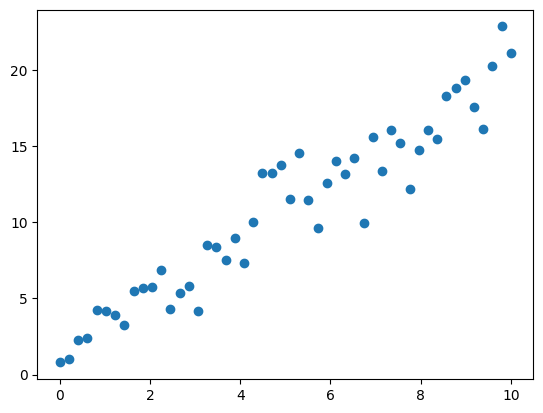

In [30]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(238)
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + np.random.randn(50) * 2
plt.scatter(X, y)
plt.show()

In [31]:
type(X)

numpy.ndarray

In [32]:
type(y)

numpy.ndarray

In [33]:
X[:10]

array([0.        , 0.20408163, 0.40816327, 0.6122449 , 0.81632653,
       1.02040816, 1.2244898 , 1.42857143, 1.63265306, 1.83673469])

In [34]:
y[:10]

array([0.79104281, 1.0212283 , 2.25247534, 2.42682996, 4.25245237,
       4.16108715, 3.94257182, 3.27698626, 5.45959711, 5.69119986])

In [35]:
# === hiperparámetros ===
learning_rate = 0.001 #usar 0.1, 0.5, 0.0001
epochs = 50           #usar 10, 50, 100
# ============================================

a, b = 0.0, 0.0
for _ in range(epochs):
    y_pred = a * X + b
    da = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)
    a -= learning_rate * da
    b -= learning_rate * db

In [36]:
# se han aprendido los coeficientes a y b
print(f"{a:.2f} * x + {b:.2f} = y")

1.98 * x + 0.33 = y


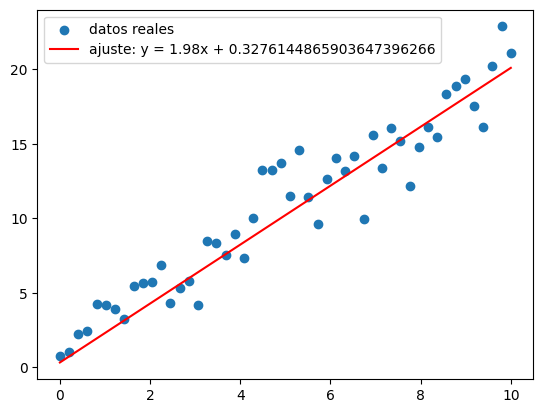

In [37]:
# se representan los puntos y la recta
plt.scatter(X, y, label="datos reales")
plt.plot(X, a * X + b, color="red", label=f"ajuste: y = {a:2.2f}x + {b:.22f}")
plt.legend()
plt.show()

In [38]:
# evaluar con datos que el modelo nunca ha visto
# aquí realizamos la evaluación de todos los datos de prueba
# el resultado se convierte en un array unidimensional
y_pred = a * X.flatten() + b
# aquí se calcula el error cuadrático medio
# np.mean: calcula la media de los errores al cuadrado
mse_test = np.mean((y_pred - y) ** 2)

print(f"Error cuadrático medio en PRUEBA: {mse_test:,.0f} €²")
print(f"Error absoluto medio en PRUEBA: {np.mean(np.abs(y_pred - y)):,.0f} €")

Error cuadrático medio en PRUEBA: 3 €²
Error absoluto medio en PRUEBA: 1 €


```
"Si mañana llega un piso de 200 m²,
¿confiarías en la predicción del modelo?
¿Qué pasaría si el modelo solo ha visto
pisos de 40 a 100 m²? ¿Por qué?"
```

La respuesta introduce un concepto crucial: el modelo solo es fiable dentro del rango de datos que ha visto. Fuera de ahí, extrapola y puede decir barbaridades. Eso conecta con la idea de incertidumbre que ya se vio en K-Means: el modelo no sabe que no sabe.



---



El dataset "Properties for sale or rent in Spain" de Zenodo contiene 542 registros de propiedades en España con 19 columnas que incluyen Sale_Price (precio de venta en euros), Surface (superficie en m²), Bedrooms, Bathrooms, Year_Construction, City y Property_Type. Es perfecto porque:

    Tiene la relación directa superficie → precio para la regresión lineal.

    Los datos son reales del mercado español.

    Se carga directamente en Colab desde el enlace de Zenodo sin necesidad de registrarse.



In [39]:
import pandas as pd

url = "https://zenodo.org/records/14028180/files/properties_Spain.csv"
df = pd.read_csv(url)
type(df)

pandas.core.frame.DataFrame

In [40]:
df.head()

,Energy_Consumption,Reference,Heating,Country,City,Zone,Energy_Class,Publish_date,Sale_Price,Floor,Street,Bedrooms,Elevator,Bathrooms,Year_Construction,Surface,Autonomous_Community,Contrat,Property_Type
0,"42,06 kW h/m&sup2; año",594509,NaN,es,Almería,NaN,g,2024-09-13 17:32:47,105000,1,Calle Quinta Avenida,3 dorm.,NaN,1 baño,1969,88.0,Andalucía,venta,Popular
1,NaN,599139,NaN,es,Almería,NaN,NaN,2024-10-25 19:44:05,97990,Baja,C. Cámaras,3 dorm.,NaN,1 baño,1960,111.0,Andalucía,venta,Popular
2,NaN,599242,NaN,es,Almería,NaN,NaN,2024-10-25 19:26:17,59990,NaN,C. Zagal,3 dorm.,NaN,NaN,1954,51.0,Andalucía,venta,Media
3,NaN,598061,NaN,es,Almería,NaN,NaN,2024-10-18 16:40:37,119000,2,Calle Marchales,3 dorm.,NaN,1 baño,1974,106.0,Andalucía,venta,Popular
4,NaN,532627,NaN,es,Almería,NaN,NaN,2024-10-16 09:53:10,159500,NaN,C. Maldonado Entrena,4 dorm.,NaN,2 baños,1975,172.0,Andalucía,venta,Popular


In [41]:
# limpieza de datos
# se borran los registros que tengan valores nulos en alguno de los dos campos indicados
df = df.dropna(subset=["Sale_Price", "Surface"])
# se filtran los registros que en el campo indicado tengan el valor especificado
df = df[df["Contrat"] == "venta"]
# filtrar valores extremos poco realistas: outliers
df = df[(df["Sale_Price"] > 10000) & (df["Sale_Price"] < 2000000)]
df = df[(df["Surface"] > 20) & (df["Surface"] < 500)]

In [42]:
# se visualizan los campos indicados de los primeros registros
df[["Sale_Price", "Surface", "Bedrooms", "Bathrooms"]].head()

,Sale_Price,Surface,Bedrooms,Bathrooms
0,105000,88.0,3 dorm.,1 baño
1,97990,111.0,3 dorm.,1 baño
2,59990,51.0,3 dorm.,NaN
3,119000,106.0,3 dorm.,1 baño
4,159500,172.0,4 dorm.,2 baños


In [43]:
print(f"Número de viviendas: {len(df)}")
print(df[["Sale_Price", "Surface"]].describe())

Número de viviendas: 428
         Sale_Price     Surface
count  4.280000e+02  428.000000
mean   2.008351e+05  114.151869
std    1.723698e+05   63.258422
min    1.850000e+04   27.000000
25%    9.497500e+04   75.000000
50%    1.559500e+05   94.000000
75%    2.590000e+05  130.500000
max    1.890000e+06  454.000000


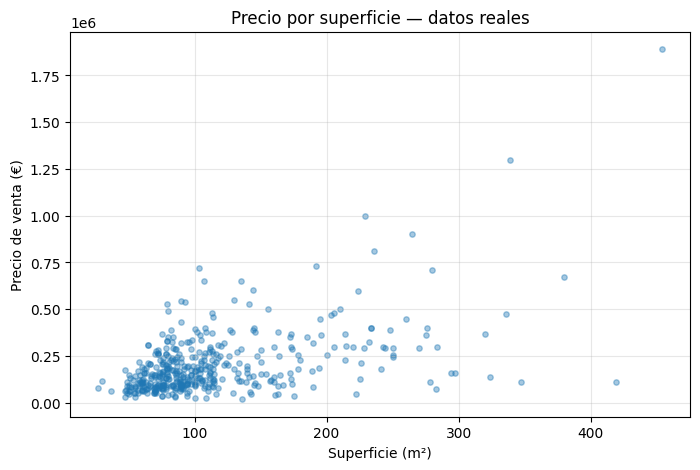

In [44]:
# representamos gráficamente los puntos
plt.figure(figsize=(8, 5))
plt.scatter(df["Surface"], df["Sale_Price"], alpha=0.4, s=15)
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio de venta (€)")
plt.title("Precio por superficie — datos reales")
plt.grid(True, alpha=0.3)
plt.show()

In [45]:
# transformando los datos
# se normalizan para que se mas fácil tratarlos
print(type(df["Surface"]))
print(type(df["Surface"].values))
print(type(df["Surface"].values.reshape(-1, 1)))
print(df["Surface"].values[:5])
print(df["Surface"].values.reshape(-1, 1)[:5])
print("dimensiones", df["Surface"].values.ndim)
print("forma", df["Surface"].values.shape)
print("tamaño", df["Surface"].values.size)
print("dimensiones", df["Surface"].values.reshape(-1, 1).ndim)
print("forma", df["Surface"].values.reshape(-1, 1).shape)
print("tamaño", df["Surface"].values.reshape(-1, 1).size)

<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
[ 88. 111.  51. 106. 172.]
[[ 88.]
 [111.]
 [ 51.]
 [106.]
 [172.]]
dimensiones 1
forma (428,)
tamaño 428
dimensiones 2
forma (428, 1)
tamaño 428


In [46]:
from sklearn.model_selection import train_test_split

#los datos de entrada son el array unidimensional
#que se debe transformar en
#un array bidimensional
#es habitual nombrar X el conjunto de datos e y el conjunto de resultados
X = df["Surface"].values.reshape(-1, 1)  # entrada, debe ser bidimensional
y = df["Sale_Price"].values              # salida, unidimensional

# el 80% de los datos para entrenar y el 20% de los datos para evaluar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {len(X_train)} viviendas")
print(f"Prueba: {len(X_test)} viviendas")

Entrenamiento: 342 viviendas
Prueba: 86 viviendas


In [47]:
# ================================================
# MODIFICA ESTOS DOS NÚMEROS Y EJECUTA
learning_rate = 0.00001    # prueba con 0.1, 0.000001, 0.00000001
epochs = 10                # prueba con 5, 20, 100
# ================================================

# Parámetros iniciales
a = 0.0   # pendiente
b = 0.0   # ordenada en el origen

n = len(X_train)

for epoch in range(epochs):
    # Predicción
    y_pred = a * X_train.flatten() + b

    # Error
    error = y_pred - y_train

    # Gradientes
    da = (2 / n) * np.sum(error * X_train.flatten())
    db = (2 / n) * np.sum(error)

    # Actualizar parámetros
    a = a - learning_rate * da
    b = b - learning_rate * db

    # Mostrar error cada cierto número de épocas
    if epoch % max(1, epochs // 5) == 0:
        mse = np.mean(error ** 2)
        print(f"Época {epoch:3d} | MSE: {mse:,.0f} | a: {a:.2f} | b: {b:.2f}")

print(f"\nParámetros finales: a = {a:.2f}, b = {b:.2f}")
print(f"Recta aprendida: precio = {a:.2f} × superficie + {b:.2f}")

Época   0 | MSE: 72,485,852,612 | a: 585.08 | b: 4.06
Época   2 | MSE: 31,396,575,384 | a: 1232.60 | b: 8.64
Época   4 | MSE: 23,371,557,673 | a: 1518.76 | b: 10.77
Época   6 | MSE: 21,804,215,578 | a: 1645.23 | b: 11.81
Época   8 | MSE: 21,498,101,618 | a: 1701.12 | b: 12.37

Parámetros finales: a = 1715.95, b = 12.56
Recta aprendida: precio = 1715.95 × superficie + 12.56


In [48]:
# Comparación de hiperparámetros con la misma partición del cuaderno.
from sklearn.model_selection import KFold

def entrenar_descenso(x, y, tasa, epocas):
    x = np.asarray(x).ravel()
    a, b = 0.0, 0.0
    historial = [np.mean(y ** 2)]
    for _ in range(epocas):
        error = a * x + b - y
        a -= 2 * tasa * np.mean(error * x)
        b -= 2 * tasa * np.mean(error)
        with np.errstate(over="ignore"):
            mse = np.mean((a * x + b - y) ** 2)
        historial.append(mse)
        if not np.isfinite(mse):
            break
    return a, b, np.array(historial)


tasas = [0.1, 1e-5, 1e-6, 1e-8]
lista_epocas = [5, 10, 20, 100]
particiones = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X_train))
col_mse = "MSE de entrenamiento (€²)"
col_cv = "MSE de validación (€²)"
filas = []
for tasa in tasas:
    for num_epocas in lista_epocas:
        pendiente, intercepto, perdidas = entrenar_descenso(
            X_train, y_train, tasa, num_epocas
        )
        mse_folds = []
        for idx_ajuste, idx_val in particiones:
            a_cv, b_cv, curva_cv = entrenar_descenso(
                X_train[idx_ajuste], y_train[idx_ajuste], tasa, num_epocas
            )
            if not np.isfinite(curva_cv[-1]):
                mse_folds.append(np.inf)
                continue
            with np.errstate(over="ignore"):
                error_val = a_cv * X_train[idx_val].ravel() + b_cv - y_train[idx_val]
                mse_folds.append(np.mean(error_val ** 2))
        filas.append({
            "Tasa": tasa,
            "Épocas": num_epocas,
            col_mse: perdidas[-1],
            col_cv: np.mean(mse_folds),
            "Comportamiento": "Diverge" if perdidas[-1] > perdidas[0] else "Reduce el error",
            "a": pendiente,
            "b": intercepto,
        })

resultados = pd.DataFrame(filas)
mejor = resultados.loc[resultados[col_cv].idxmin()]
a_mejor, b_mejor = mejor["a"], mejor["b"]
display(resultados.drop(columns=["a", "b"]).style.format({
    "Tasa": "{:.0e}", col_mse: "{:.9e}", col_cv: "{:.9e}"
}))
print(f"Mejor por validación cruzada (5 particiones): tasa={mejor['Tasa']:g}, épocas={mejor['Épocas']}")
print(f"Recta: precio = {a_mejor:.2f} × superficie + {b_mejor:.2f}")

,Tasa,Épocas,MSE de entrenamiento (€²),MSE de validación (€²),Comportamiento
0,1e-01,5,9.121655177e+45,9.180102418e+45,Diverge
1,1e-01,10,1.629480373e+81,1.726441496e+81,Diverge
2,1e-01,20,5.199961166e+151,6.982624848e+151,Diverge
3,1e-01,100,inf,inf,Diverge
4,1e-05,5,2.228458685e+10,2.311114351e+10,Reduce el error
5,1e-05,10,2.143831412e+10,2.230881647e+10,Reduce el error
6,1e-05,20,2.142379927e+10,2.229395655e+10,Reduce el error
7,1e-05,100,2.142372816e+10,2.229397479e+10,Reduce el error
8,1e-06,5,5.773319407e+10,5.793432850e+10,Reduce el error
9,1e-06,10,4.724281958e+10,4.758349190e+10,Reduce el error


Mejor por validación cruzada (5 particiones): tasa=1e-05, épocas=20
Recta: precio = 1744.87 × superficie + 13.67


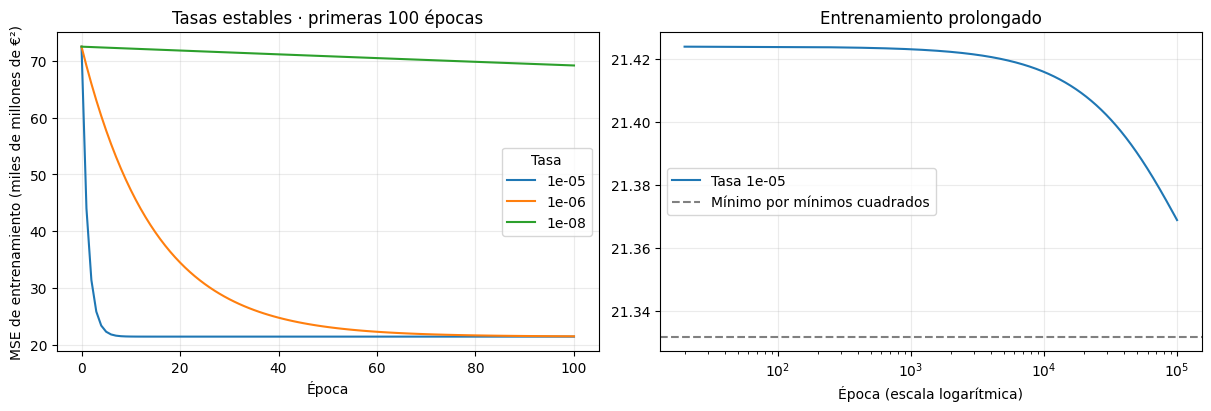

      5 épocas   MSE =    22,284,586,846 €²
     10 épocas   MSE =    21,438,314,124 €²
     20 épocas   MSE =    21,423,799,273 €²
    100 épocas   MSE =    21,423,728,164 €²
  1,000 épocas   MSE =    21,422,977,930 €²
 10,000 épocas   MSE =    21,415,804,578 €²
100,000 épocas   MSE =    21,368,841,173 €²
Mejora relativa de 20 a 100 épocas: 0.000332 %
MSE mínimo de referencia: 21,331,899,982 €²
Intercepto a las 100 épocas: 21.00 €. A las 100 000: 7362.78 €
Límite teórico de estabilidad de la tasa: 5.97e-05


In [49]:
# Curvas de aprendizaje y comprobación de la meseta.
x_ent = X_train.ravel()
diseno = np.column_stack((x_ent, np.ones_like(x_ent)))
coef_optimos = np.linalg.lstsq(diseno, y_train, rcond=None)[0]
mse_optimo = np.mean((diseno @ coef_optimos - y_train) ** 2)
hessiana = 2 * diseno.T @ diseno / len(y_train)
tasa_limite = 2 / np.linalg.eigvalsh(hessiana)[-1]

_, b_largo, curva_larga = entrenar_descenso(X_train, y_train, mejor["Tasa"], 100_000)
_, b_100, _ = entrenar_descenso(X_train, y_train, mejor["Tasa"], 100)
fig, (ax_corto, ax_largo) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for tasa in tasas:
    if tasa < tasa_limite:
        _, _, curva = entrenar_descenso(X_train, y_train, tasa, 100)
        ax_corto.plot(np.arange(len(curva)), curva / 1e9, label=f"{tasa:g}")
ax_corto.set(title="Tasas estables · primeras 100 épocas", xlabel="Época",
             ylabel="MSE de entrenamiento (miles de millones de €²)")
ax_corto.legend(title="Tasa")

ax_largo.semilogx(np.arange(20, len(curva_larga)), curva_larga[20:] / 1e9,
                 label=f"Tasa {mejor['Tasa']:g}")
ax_largo.axhline(mse_optimo / 1e9, color="gray", linestyle="--", label="Mínimo por mínimos cuadrados")
ax_largo.set(title="Entrenamiento prolongado", xlabel="Época (escala logarítmica)")
ax_largo.legend()
for ax in (ax_corto, ax_largo):
    ax.grid(alpha=0.25)
plt.show()

puntos = [5, 10, 20, 100, 1_000, 10_000, 100_000]
for n_epocas in puntos:
    print(f"{n_epocas:>7,} épocas   MSE = {curva_larga[n_epocas]:>17,.0f} €²")
mejora_20_100 = 100 * (1 - curva_larga[100] / curva_larga[20])
print(f"Mejora relativa de 20 a 100 épocas: {mejora_20_100:.6f} %")
print(f"MSE mínimo de referencia: {mse_optimo:,.0f} €²")
print(f"Intercepto a las 100 épocas: {b_100:.2f} €. A las 100 000: {b_largo:.2f} €")
print(f"Límite teórico de estabilidad de la tasa: {tasa_limite:.3g}")

In [50]:
# Comprobación de las tasas sugeridas en el ejemplo de datos sintéticos.
x_sint = np.linspace(0, 10, 50)
y_sint = 2 * x_sint + 1 + 2 * np.random.RandomState(238).randn(50)
tasas_sint = [0.5, 0.1, 0.001, 0.0001]
epocas_sint = [10, 50, 100]
resumen_sint = pd.DataFrame(index=tasas_sint, columns=epocas_sint, dtype=object)
for tasa in tasas_sint:
    for num_epocas in epocas_sint:
        _, _, curva = entrenar_descenso(x_sint, y_sint, tasa, num_epocas)
        resumen_sint.loc[tasa, num_epocas] = (
            f"{curva[-1]:.3f}" if curva[-1] < curva[0] else "Diverge"
        )
resumen_sint.index.name = "Tasa"
resumen_sint.columns.name = "Épocas"
print("Ejemplo sintético · MSE sobre los 50 puntos del ejemplo")
display(resumen_sint)

Ejemplo sintético · MSE sobre los 50 puntos del ejemplo


Épocas,10,50,100
Tasa,,,
0.5000,Diverge,Diverge,Diverge
0.1000,Diverge,Diverge,Diverge
0.0010,38.317,3.286,3.151
0.0001,130.608,76.508,39.931


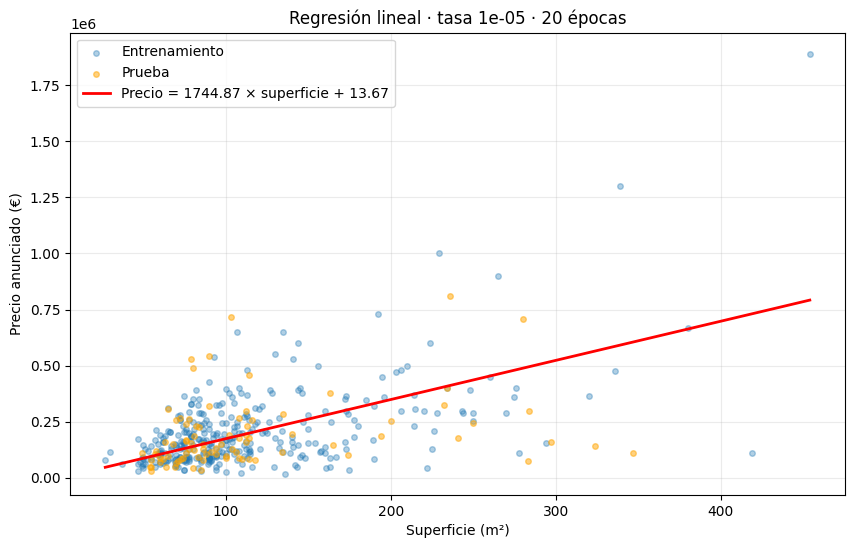

In [51]:
# Recta de la configuración seleccionada por validación cruzada.
plt.figure(figsize=(10, 6))
plt.scatter(X_train.ravel(), y_train, alpha=0.35, s=16, label="Entrenamiento")
plt.scatter(X_test.ravel(), y_test, alpha=0.5, s=16, color="orange", label="Prueba")
x_linea = np.linspace(X_train.min(), X_train.max(), 100)
plt.plot(x_linea, a_mejor * x_linea + b_mejor, color="red", linewidth=2,
         label=f"Precio = {a_mejor:.2f} × superficie + {b_mejor:.2f}")
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio anunciado (€)")
plt.title(f"Regresión lineal · tasa {mejor['Tasa']:g} · {mejor['Épocas']} épocas")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

¿Cómo funciona el algoritmo usando diferentes hiperparámetros? ¿Con qué hiperparámetros se obtiene el mejor modelo? ¿Hay algún número de épocas a partir del cual el modelo ya no aprende más?

### Respuesta

**Efecto de los hiperparámetros.** En los datos de viviendas, la tasa 0,1 hace divergir el descenso del gradiente porque los pasos son demasiado grandes para la escala de la superficie. Con 0,00000001 el error baja muy despacio. Con 0,000001 hace falta más tiempo para acercarse al ajuste que 0,00001 alcanza en unas 20 épocas. En el ejemplo sintético también divergen 0,1 y 0,5. Allí, 0,001 con 100 épocas obtiene el menor MSE de las combinaciones probadas (3,151 sobre los 50 puntos).

**Mejor configuración para las viviendas.** De las 16 combinaciones, la tasa **0,00001 con 20 épocas** obtuvo el menor MSE medio en una validación cruzada de cinco particiones sobre las 342 viviendas de entrenamiento: **22.293.956.549 €²**. Al ajustar esa configuración con las 342 viviendas, la recta resultante es **precio = 1.744,87 × superficie + 13,67**.

**¿Cuándo deja de mejorar?** Con esa tasa, hacia la época 20 aparece una meseta. De 20 a 100 épocas el MSE de entrenamiento cae solo un **0,000332 %** y el de validación apenas cambia. Si se sigue entrenando, el error todavía baja lentamente porque el intercepto tarda más en ajustarse que la pendiente. El momento en que la mejora se vuelve pequeña depende de la tasa y de la escala de los datos.

**Prueba con 86 viviendas reservadas.** El modelo obtuvo un **MSE de 26.767.082.262 €²** y un **MAE de 109.700 €**. Predecir siempre el precio medio del conjunto de entrenamiento dio un MSE de **23.389.819.155 €²**, menor en esta prueba. La superficie por sí sola deja sin explicar diferencias de precio debidas a factores como la ubicación, la antigüedad o el estado de la vivienda.

In [52]:
# Evaluación final sobre las 86 viviendas reservadas para prueba.
y_test_pred = a_mejor * X_test.ravel() + b_mejor
error_prueba = y_test_pred - y_test
mse_test = np.mean(error_prueba ** 2)
mae_test = np.mean(np.abs(error_prueba))
print(f"MSE de prueba: {mse_test:,.0f} €²")
print(f"MAE de prueba: {mae_test:,.0f} €")

# Referencia: predecir siempre el precio medio del conjunto de entrenamiento.
mse_media = np.mean((y_train.mean() - y_test) ** 2)
print(f"MSE de prueba al predecir el precio medio: {mse_media:,.0f} €²")

MSE de prueba: 26,767,082,262 €²
MAE de prueba: 109,700 €
MSE de prueba al predecir el precio medio: 23,389,819,155 €²


¿Por qué predecir el precio solo con la superficie no es suficiente? Porque el precio también depende de la ciudad, la planta, el año de construcción, el número de habitaciones... Eso abre la puerta a la regresión lineal múltiple, donde el modelo ya no usa una sola x, sino varias. La clase LinearRegression() de scikit-learn sirve exactamente para eso, y sería el siguiente paso lógico.